In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import datetime as dt
import numpy as np
from scipy.optimize import minimize, minimize_scalar

from russian_rates.analysis import (
    load_rates,
)

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Откройте Jupyter из папки репозитория russian-interest-rate-models.")
DATA_DIR = ROOT / "data" / "processed"

data = load_rates(DATA_DIR)
ruonia = data["ruonia"]
key_rate = data["key_rate"]
zcyc = data["zcyc"]

In [2]:
ruonia_wide = ruonia.drop(columns='volume_bln_rub').sort_values(by="date", ascending=True).copy()
ruonia_wide["ruonia_pct"] = ruonia_wide["ruonia_pct"] / 100

In [3]:
ruonia_wide['r_prev'] = ruonia_wide["ruonia_pct"].shift(1)
ruonia_wide['dt'] = ((ruonia_wide['date'] - ruonia_wide['date'].shift(1)).dt.days.dropna().astype(int)) / 365
pairs = ruonia_wide.dropna(subset=["r_prev", "dt"]).copy()
assert (pairs["dt"] > 0).all()

In [4]:
r_prev = pairs["r_prev"].to_numpy(dtype=float)
r_next = pairs["ruonia_pct"].to_numpy(dtype=float)
dt = pairs["dt"].to_numpy(dtype=float)

In [5]:
def vasicek_nll(params, r_prev, r_next, dt):
    a, b, sigma = params

    if a <= 0 or sigma <= 0:
        return np.inf

    # Экспоненциальный коэффициент возврата
    phi = np.exp(-a * dt)

    # Условное математическое ожидание
    mu = b + (r_prev - b) * phi

    # Условная дисперсия
    var = (
        sigma**2
        * (-np.expm1(-2 * a * dt))
        / (2 * a)
    )

    # Отрицательное логарифмическое правдоподобие
    nll = 0.5 * np.sum(
        np.log(2 * np.pi * var)
        + (r_next - mu)**2 / var
    )

    return nll

In [6]:
params = [0.5, 0.1, 0.03]
vasicek_nll(params, r_prev, r_next, dt)

np.float64(-11489.751172016335)

In [7]:
# Поиск оптимальных параметров

# первоначальные приближения
a0 = 0.5
b0 = float(np.mean(r_next))

sigma0 = max(
    1e-5,
    float(np.sqrt(np.mean(
        (r_next - r_prev)**2 / dt
    )))
)

result = minimize(
    fun=vasicek_nll,
    x0=[a0, b0, sigma0],
    args=(r_prev, r_next, dt),
    method="L-BFGS-B",
    bounds=[
        (1e-5, 50), # a > 0
        (None, None), # b без ограничений
        (1e-6, None), # sigma > 0
    ]
)

if not result.success:
    raise RuntimeError(result.message)

print("Optimization success:", result.success)
print("Message:", result.message)

a, b, sigma = result.x

print(f"a = {a:.6f} 1/год")
print(f"b = {b * 100:.4f}%")
print(f"sigma = {sigma * 100:.4f} п.п./√год")

print(f"Half-life = {np.log(2) / a:.3f} года")
print(f"NLL = {result.fun:.4f}")

print("Parameters at bounds:")
print("a at upper bound:", np.isclose(a, 50))
print("sigma at lower bound:", np.isclose(sigma, 1e-6))

Optimization success: True
Message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
a = 0.778781 1/год
b = 11.3273%
sigma = 5.6725 п.п./√год
Half-life = 0.890 года
NLL = -13546.0864
Parameters at bounds:
a at upper bound: False
sigma at lower bound: False


In [8]:
for a0 in [0.1, 0.5, 1, 3, 10]:
    result = minimize(
        fun=vasicek_nll,
        x0=[a0, b0, sigma0],
        args=(r_prev, r_next, dt),
        method="L-BFGS-B",
        bounds=[
            (1e-5, 50),
            (None, None),
            (1e-6, None),
        ],
    )

    a, b, sigma = result.x

    print(
        f"a0={a0:5.2f} | "
        f"a={a:.5f} | "
        f"b={b*100:.3f}% | "
        f"sigma={sigma*100:.3f} | "
        f"NLL={result.fun:.4f} | "
        f"success={result.success}"
    )

a0= 0.10 | a=0.77877 | b=11.327% | sigma=5.673 | NLL=-13546.0864 | success=True
a0= 0.50 | a=0.77878 | b=11.327% | sigma=5.673 | NLL=-13546.0864 | success=True
a0= 1.00 | a=0.99945 | b=11.144% | sigma=5.676 | NLL=-13545.8804 | success=True
a0= 3.00 | a=0.77882 | b=11.327% | sigma=5.673 | NLL=-13546.0864 | success=True
a0=10.00 | a=0.77879 | b=11.327% | sigma=5.673 | NLL=-13546.0864 | success=True


a = 0.7788016403053939
NLL = -13546.086371929927


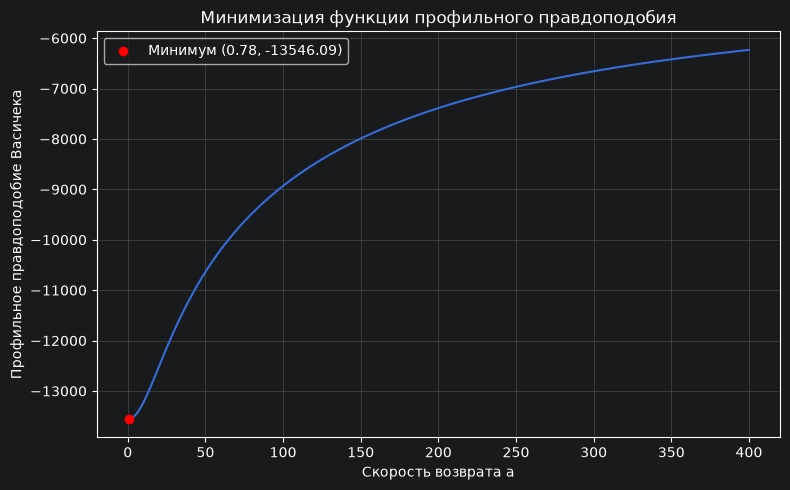

In [11]:
# Профильное правдоподобие - фиксирование a0 и подбор оптимальных b и σ
def profile_nll(a):
    phi = np.exp(-a * dt)

    q = -np.expm1(-2 * a * dt) / (2 * a)

    x = 1 - phi
    y = r_next - phi * r_prev

    # Оптимальный b при заданном a
    b = np.sum(x * y / q) / np.sum(x**2 / q)

    residuals = y - b * x

    # Оптимальный sigma при заданном a
    sigma2 = np.mean(residuals**2 / q)

    var = sigma2 * q

    nll = 0.5 * np.sum(
        np.log(2 * np.pi * var)
        + residuals**2 / var
    )

    return nll


result_profile = minimize_scalar(
    profile_nll,
    bounds=(0.01, 20),
    method="bounded"
)

print("a =", result_profile.x)
print("NLL =", result_profile.fun)



x_vals = np.linspace(0.01, 400, 3165)
y_vals = [profile_nll(x) for x in x_vals]

plt.figure(figsize=(8, 5))
plt.plot(x_vals, y_vals)
plt.scatter(
    result_profile.x,
    result_profile.fun,
    color="red",
    zorder=5,
    label=f"Минимум ({result_profile.x:.2f}, {result_profile.fun:.2f})"
)

plt.title("Минимизация функции профильного правдоподобия")
plt.xlabel("Скорость возврата a")
plt.ylabel("Профильное правдоподобие Васичека")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()